# Quantum reservoir computing for chaotic time series

A six-qubit quantum reservoir is simulated with Qiskit and used to forecast two chaotic benchmark systems, the Lorenz-63 attractor and the Mackey–Glass delay equation. The input is encoded in the evolution time of a transverse Ising-type circuit, single-qubit Pauli expectation values and their squares form the feature vector, and only a linear readout is trained.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Pauli, Statevector
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

N_QUBITS = 6
T0 = 0.5
ALPHA = 1.0
SEED = 42
TEST_FRACTION = 0.2

COLOR_TRUE = "#2a78d6"
COLOR_PRED = "#eb6834"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "lines.linewidth": 1.6,
    "legend.frameon": False,
})

## Reservoir

Each reservoir layer applies $R_Z(-2\omega_i T_i)$ on every qubit and $R_{XX}(-(T_i+T_j)J_{ij})$ on every pair, with random frequencies $\omega_i$ and couplings $J_{ij}$. The evolution times $T_i$ carry the input signal.

In [2]:
def random_hamiltonian(rng):
    omega = rng.uniform(0.5, 1.5, size=N_QUBITS)
    J = np.zeros((N_QUBITS, N_QUBITS))
    for i in range(N_QUBITS):
        for j in range(i + 1, N_QUBITS):
            J[i, j] = J[j, i] = rng.uniform(0.1, 0.5)
    return omega, J


def evolution_layer(times, omega, J):
    qc = QuantumCircuit(N_QUBITS)
    for q in range(N_QUBITS):
        qc.rz(-2 * omega[q] * times[q], q)
    for i in range(N_QUBITS):
        for j in range(i + 1, N_QUBITS):
            qc.rxx(-(times[i] + times[j]) * J[i, j], i, j)
    return qc


def pauli_features(state, paulis):
    values = np.array([
        state.expectation_value(Pauli("I" * (N_QUBITS - 1 - q) + p + "I" * q)).real
        for p in paulis
        for q in range(N_QUBITS)
    ])
    return np.concatenate([values, values**2])


def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


PLUS_STATE = Statevector.from_label("+" * N_QUBITS)

## Lorenz-63

The three Lorenz coordinates are mapped to the evolution times of the six qubits, and the readout is trained to predict the state one integration step ahead. The trained model is evaluated in two modes: open loop, where the true state is fed in at every step, and closed loop, where the model runs autonomously on its own predictions.

In [3]:
LORENZ_DT = 0.01
LORENZ_STEPS = 5000


def lorenz_derivative(state, sigma=10.0, rho=28.0, beta=8.0 / 3.0):
    x, y, z = state
    return np.array([sigma * (y - x), x * (rho - z) - y, x * y - beta * z])


def integrate_lorenz(initial_state, dt, steps):
    trajectory = np.zeros((steps, 3))
    state = np.array(initial_state, dtype=float)
    for i in range(steps):
        k1 = lorenz_derivative(state)
        k2 = lorenz_derivative(state + 0.5 * dt * k1)
        k3 = lorenz_derivative(state + 0.5 * dt * k2)
        k4 = lorenz_derivative(state + dt * k3)
        state = state + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)
        trajectory[i] = state
    return trajectory


def lorenz_features(state, omega, J):
    times = T0 + ALPHA * np.tanh(np.asarray(state)[np.arange(N_QUBITS) % 3] / 30.0)
    return pauli_features(PLUS_STATE.evolve(evolution_layer(times, omega, J)), "ZXY")


omega, J = random_hamiltonian(np.random.RandomState(SEED))
trajectory = integrate_lorenz([1.0, 1.0, 1.0], LORENZ_DT, LORENZ_STEPS)

X = np.array([lorenz_features(state, omega, J) for state in trajectory[:-1]])
Y = trajectory[1:]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=TEST_FRACTION, shuffle=False)

lorenz_model = LinearRegression().fit(X_train, Y_train)

lorenz_true = Y_test[1:]
lorenz_open = lorenz_model.predict(X_test[1:])

lorenz_closed = np.zeros_like(lorenz_true)
state = Y_test[0]
for i in range(len(lorenz_closed)):
    state = lorenz_model.predict([lorenz_features(state, omega, J)])[0]
    lorenz_closed[i] = state

for name, prediction in [("Open loop", lorenz_open), ("Closed loop", lorenz_closed)]:
    per_component = np.sqrt(np.mean((lorenz_true - prediction) ** 2, axis=0))
    print(f"{name:<12} RMSE = {rmse(lorenz_true, prediction):.4f}   (x, y, z) = {np.round(per_component, 4)}")

Open loop    RMSE = 0.0309   (x, y, z) = [0.0224 0.039  0.029 ]
Closed loop  RMSE = 9.7167   (x, y, z) = [ 8.8563 10.5847  9.6318]


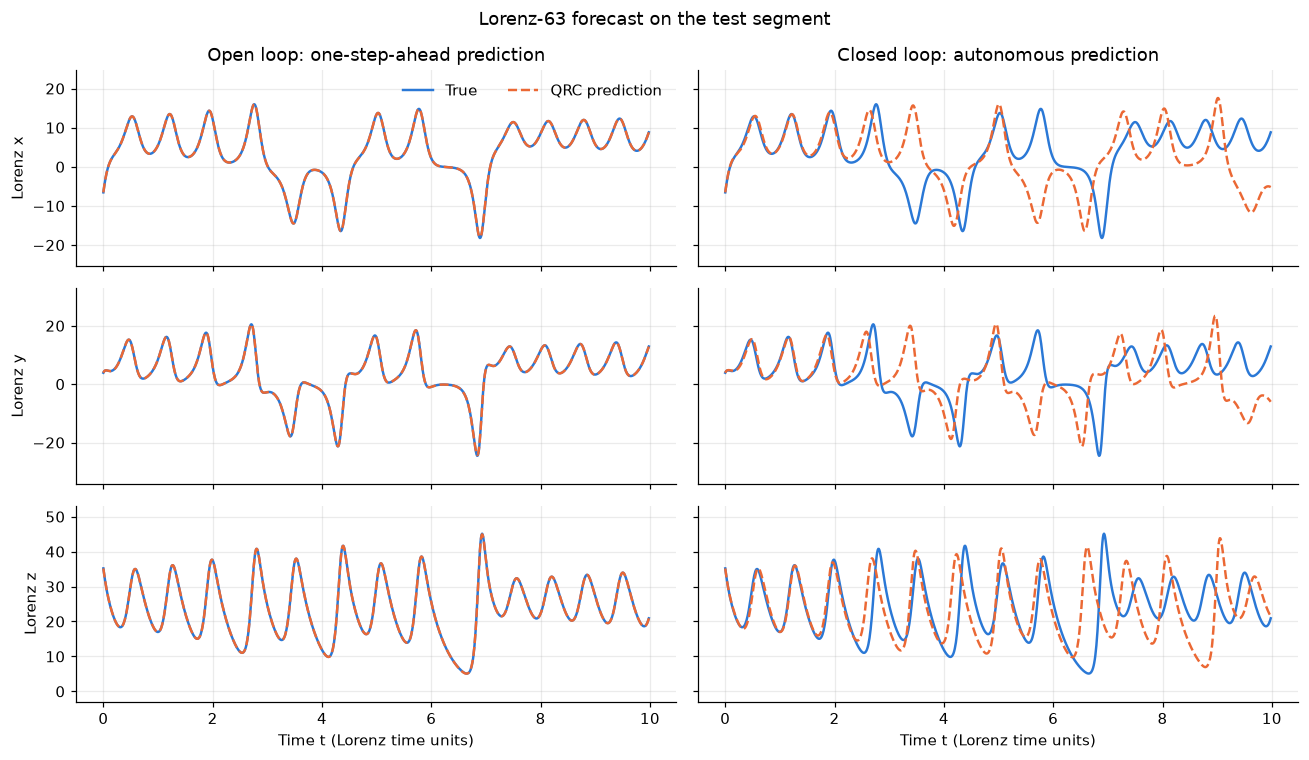

In [4]:
t = np.arange(len(lorenz_true)) * LORENZ_DT
fig, axes = plt.subplots(3, 2, figsize=(12, 7), sharex=True, sharey="row")
for col, (prediction, title) in enumerate([
    (lorenz_open, "Open loop: one-step-ahead prediction"),
    (lorenz_closed, "Closed loop: autonomous prediction"),
]):
    for row, component in enumerate("xyz"):
        ax = axes[row, col]
        ax.plot(t, lorenz_true[:, row], color=COLOR_TRUE, label="True")
        ax.plot(t, prediction[:, row], color=COLOR_PRED, linestyle="--", label="QRC prediction")
        ax.margins(y=0.2)
        if col == 0:
            ax.set_ylabel(f"Lorenz {component}")
    axes[0, col].set_title(title)
    axes[2, col].set_xlabel("Time t (Lorenz time units)")
axes[0, 0].legend(loc="upper right", ncol=2)
fig.suptitle("Lorenz-63 forecast on the test segment")
fig.tight_layout()
plt.show()

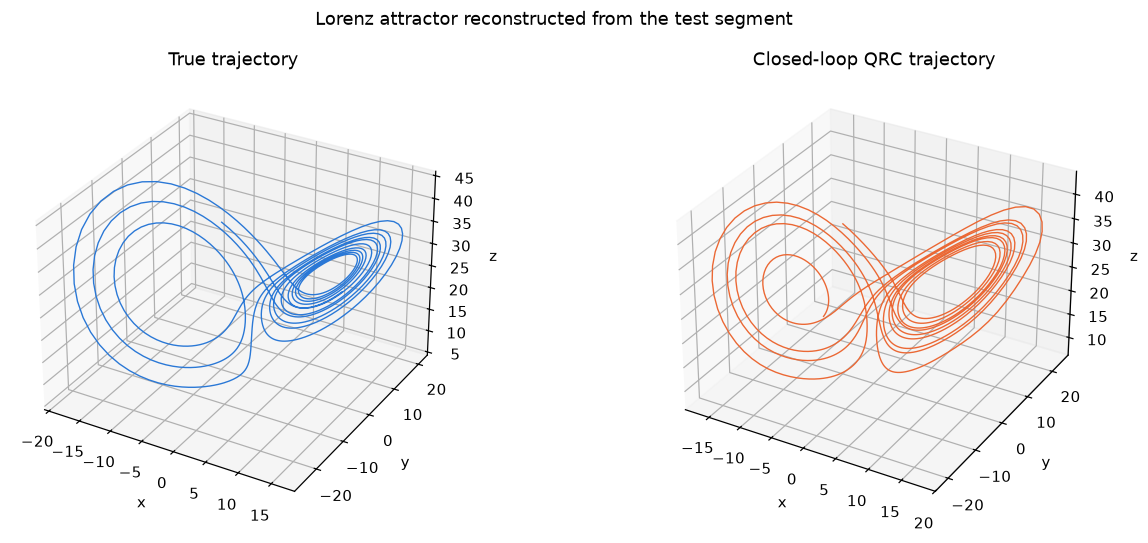

In [5]:
fig = plt.figure(figsize=(12, 5))
for k, (data, color, title) in enumerate([
    (lorenz_true, COLOR_TRUE, "True trajectory"),
    (lorenz_closed, COLOR_PRED, "Closed-loop QRC trajectory"),
]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.plot(data[:, 0], data[:, 1], data[:, 2], color=color, linewidth=0.9)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
fig.suptitle("Lorenz attractor reconstructed from the test segment")
fig.tight_layout()
plt.show()

## Mackey–Glass: open-loop forecasting

The scalar Mackey–Glass signal ($\tau = 17$) sets a common evolution time for all qubits. The readout uses $\langle Z_i \rangle$ and $\langle Z_i \rangle^2$ and is trained separately for each forecast horizon.

In [6]:
MG_BETA = 0.2
MG_GAMMA = 0.1
MG_EXPONENT = 10
MG_TAU = 17.0
MG_EULER_DT = 0.1
MG_STRIDE = 5
MG_DT = MG_EULER_DT * MG_STRIDE
MG_DELAY = int(MG_TAU / MG_DT)
MG_TRANSIENT = 20.0
EVAL_WINDOW = 2000


def mackey_glass(total_time):
    steps = int(total_time / MG_EULER_DT)
    delay = int(MG_TAU / MG_EULER_DT)
    p = np.zeros(steps)
    p[: delay + 1] = 1.2
    for i in range(delay, steps - 1):
        delayed = p[i - delay]
        p[i + 1] = p[i] + MG_EULER_DT * (MG_BETA * delayed / (1 + delayed**MG_EXPONENT) - MG_GAMMA * p[i])
    return p[int(MG_TRANSIENT / MG_EULER_DT) :: MG_STRIDE]


def scalar_time(value, mask=1.0):
    return float(np.round(T0 + ALPHA * mask * np.tanh(value / 5.0), 3))


omega, J = random_hamiltonian(np.random.RandomState(SEED))
series = mackey_glass(20000.0)
feature_cache = {}


def mackey_glass_features(value):
    key = scalar_time(value)
    if key not in feature_cache:
        state = PLUS_STATE.evolve(evolution_layer(np.full(N_QUBITS, key), omega, J))
        feature_cache[key] = pauli_features(state, "Z")
    return feature_cache[key]


def open_loop_forecast(horizon):
    X = np.array([mackey_glass_features(value) for value in series[:-horizon]])
    target_index = np.arange(horizon, len(series))
    X_train, X_test, idx_train, idx_test = train_test_split(
        X, target_index, test_size=TEST_FRACTION, shuffle=False
    )
    model = LinearRegression().fit(X_train, series[idx_train])
    idx_eval = idx_test[:EVAL_WINDOW]
    return idx_eval, model.predict(X_test[:EVAL_WINDOW])


open_loop_results = {}
for horizon in (1, 5):
    idx_eval, prediction = open_loop_forecast(horizon)
    open_loop_results[horizon] = (idx_eval, prediction)
    truth = series[idx_eval]
    print(
        f"Horizon {horizon} step(s) = {horizon * MG_DT:.1f} time units: "
        f"RMSE = {rmse(truth, prediction):.4f}, MAE = {mean_absolute_error(truth, prediction):.4f}"
    )

Horizon 1 step(s) = 0.5 time units: RMSE = 0.0167, MAE = 0.0140


Horizon 5 step(s) = 2.5 time units: RMSE = 0.0806, MAE = 0.0691


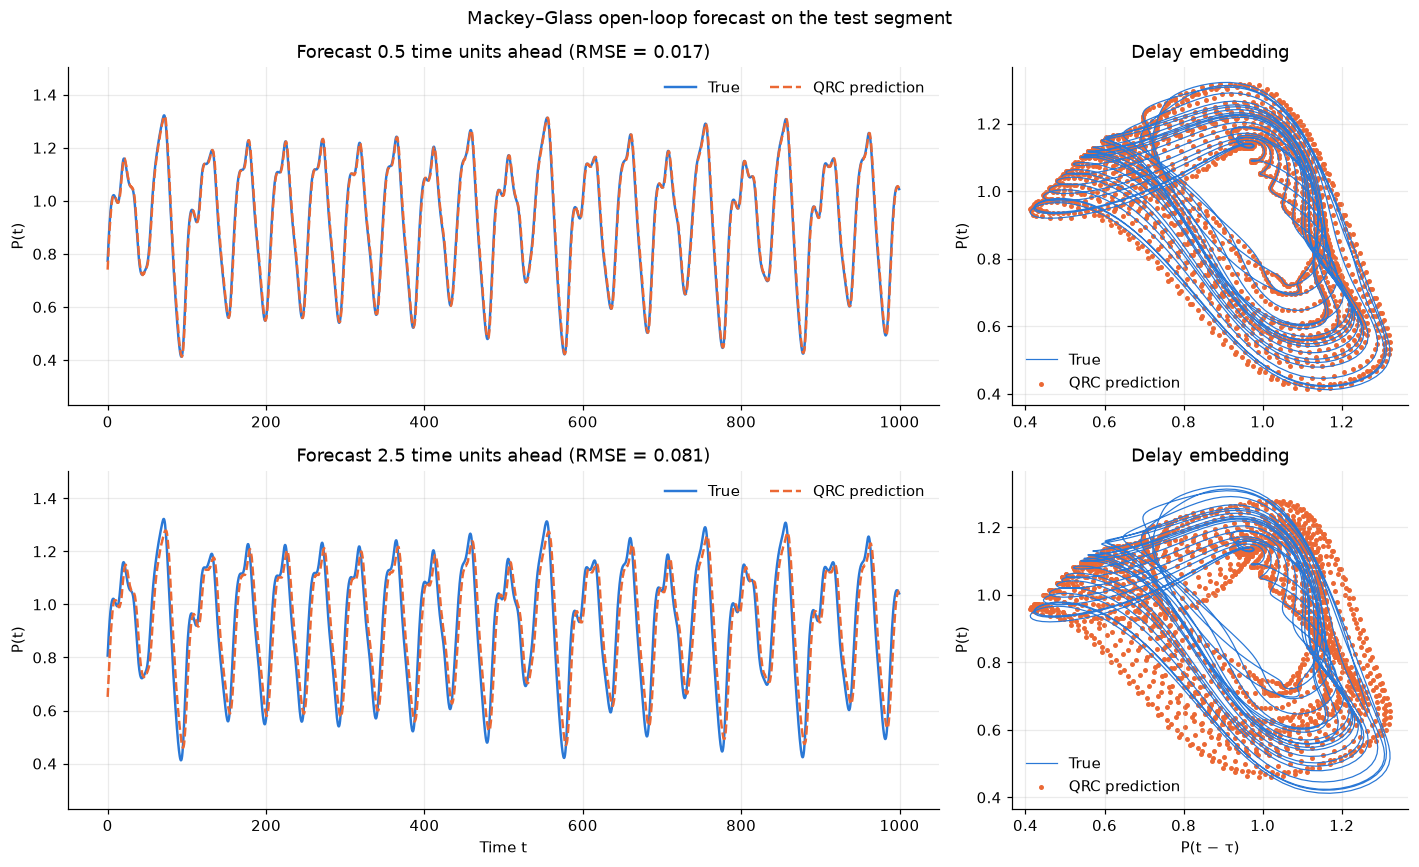

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), gridspec_kw={"width_ratios": [2.2, 1]})
for row, (horizon, (idx_eval, prediction)) in enumerate(open_loop_results.items()):
    truth = series[idx_eval]
    t = (idx_eval - idx_eval[0]) * MG_DT

    ax = axes[row, 0]
    ax.plot(t, truth, color=COLOR_TRUE, label="True")
    ax.plot(t, prediction, color=COLOR_PRED, linestyle="--", label="QRC prediction")
    ax.set_title(f"Forecast {horizon * MG_DT:.1f} time units ahead (RMSE = {rmse(truth, prediction):.3f})")
    ax.set_ylabel("P(t)")
    ax.margins(y=0.2)
    ax.legend(loc="upper right", ncol=2)

    ax = axes[row, 1]
    delayed = series[idx_eval - MG_DELAY]
    ax.plot(delayed, truth, color=COLOR_TRUE, linewidth=0.8, label="True")
    ax.scatter(delayed, prediction, color=COLOR_PRED, s=5, label="QRC prediction")
    ax.set_title("Delay embedding")
    ax.set_ylabel("P(t)")
    ax.legend(loc="lower left")
axes[1, 0].set_xlabel("Time t")
axes[1, 1].set_xlabel("P(t − τ)")
fig.suptitle("Mackey–Glass open-loop forecast on the test segment")
fig.tight_layout()
plt.show()

## Mackey–Glass: autonomous forecasting with time multiplexing

Each input value is injected through a random mask of 40 virtual nodes. Reservoir states are cached by evolution time (rounded to three decimals): the first occurrence of a time evolves the current state, and later occurrences reuse the stored state. The measured features are combined with a short tapped delay line of past values. After training with a ridge readout, the model runs in closed loop on its own output.

In [8]:
N_VIRTUAL = 40
N_TAPS = 10
RIDGE_ALPHA = 1e-6


class TimeMultiplexedReservoir:
    def __init__(self, omega, J, mask):
        self.omega = omega
        self.J = J
        self.mask = mask
        self.cache = {}
        self.state = PLUS_STATE

    def step(self, evolution_time):
        if evolution_time not in self.cache:
            layer = evolution_layer(np.full(N_QUBITS, evolution_time), self.omega, self.J)
            self.cache[evolution_time] = self.state.evolve(layer)
        self.state = self.cache[evolution_time]
        return self.state

    def features(self, value):
        return np.concatenate([
            pauli_features(self.step(scalar_time(value, m)), "Z") for m in self.mask
        ])


rng = np.random.RandomState(SEED)
mask = rng.choice([-1.0, 1.0], size=N_VIRTUAL) * rng.uniform(0.2, 1.0, size=N_VIRTUAL)
omega, J = random_hamiltonian(rng)
reservoir = TimeMultiplexedReservoir(omega, J, mask)

series_short = mackey_glass(1000.0)
input_index = np.arange(N_TAPS, len(series_short) - 1)
idx_train, idx_test = train_test_split(input_index, test_size=TEST_FRACTION, shuffle=False)

start = time.time()
X_train = np.array([
    np.concatenate([reservoir.features(series_short[i]), series_short[i - N_TAPS + 1 : i + 1]])
    for i in idx_train
])
print(f"Training set: {X_train.shape[0]} samples, {X_train.shape[1]} features, built in {time.time() - start:.1f} s")

readout = Ridge(alpha=RIDGE_ALPHA).fit(X_train, series_short[idx_train + 1])

history = list(series_short[idx_test[0] - N_TAPS + 1 : idx_test[0] + 1])
mg_closed = np.zeros(len(idx_test))
for i in range(len(idx_test)):
    features = np.concatenate([reservoir.features(history[-1]), history[-N_TAPS:]])
    mg_closed[i] = readout.predict([features])[0]
    history.append(mg_closed[i])

mg_true = series_short[idx_test + 1]
print(f"Closed loop: RMSE = {rmse(mg_true, mg_closed):.4f}, MAE = {mean_absolute_error(mg_true, mg_closed):.4f}")

Training set: 1559 samples, 490 features, built in 20.6 s


Closed loop: RMSE = 0.1702, MAE = 0.1355


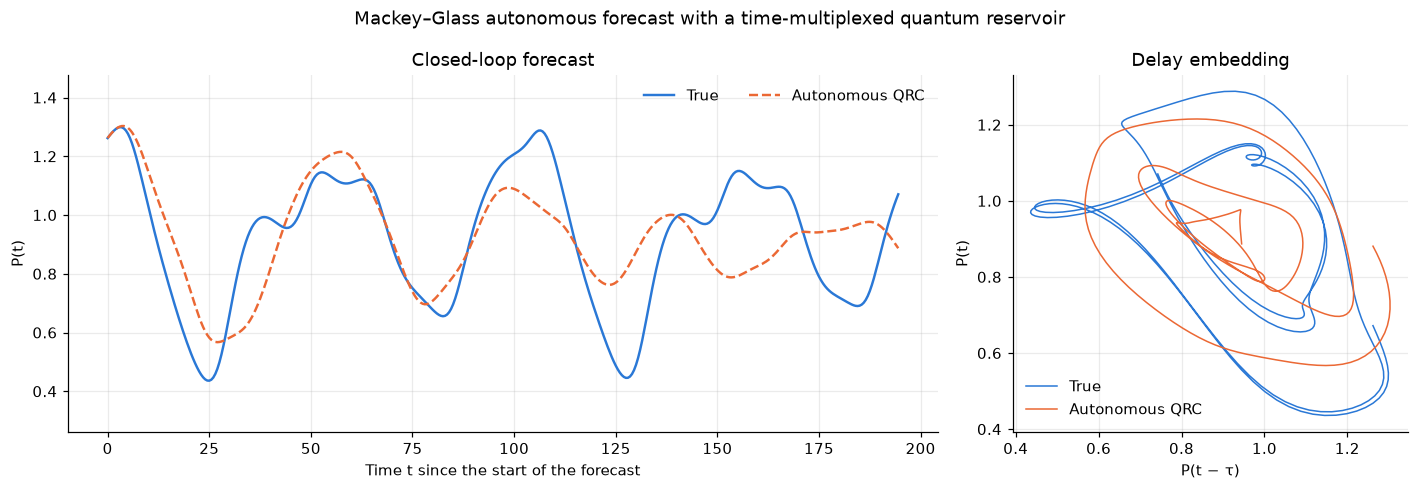

In [9]:
t = np.arange(len(mg_true)) * MG_DT
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})

axes[0].plot(t, mg_true, color=COLOR_TRUE, label="True")
axes[0].plot(t, mg_closed, color=COLOR_PRED, linestyle="--", label="Autonomous QRC")
axes[0].set_title("Closed-loop forecast")
axes[0].set_xlabel("Time t since the start of the forecast")
axes[0].set_ylabel("P(t)")
axes[0].margins(y=0.2)
axes[0].legend(loc="upper right", ncol=2)

axes[1].plot(mg_true[:-MG_DELAY], mg_true[MG_DELAY:], color=COLOR_TRUE, linewidth=1.0, label="True")
axes[1].plot(mg_closed[:-MG_DELAY], mg_closed[MG_DELAY:], color=COLOR_PRED, linewidth=1.0, label="Autonomous QRC")
axes[1].set_title("Delay embedding")
axes[1].set_xlabel("P(t − τ)")
axes[1].set_ylabel("P(t)")
axes[1].legend(loc="lower left")

fig.suptitle("Mackey–Glass autonomous forecast with a time-multiplexed quantum reservoir")
fig.tight_layout()
plt.show()